# TP1 — Statistiques météo de Dakar avec NumPy
**Environnement :** VS Code + Jupyter, environnement virtuel `.venv` en local

In [1]:
import numpy as np
print("Version de NumPy :", np.__version__)

Version de NumPy : 2.5.3


In [2]:
d = np.genfromtxt("data/meteo_dakar_2025.csv", delimiter=",",
                  names=True, dtype=None, encoding="utf-8")

print(d.dtype.names)
print(d[:3])

('date', 'mois', 'jour', 'temp_max_c', 'temp_min_c', 'humidite_pct', 'pluie_mm', 'vent_kmh')
[('2025-01-01', 1, 1, 27.1, 18.8, 66, 0., 16)
 ('2025-01-02', 1, 2, 26.7, 20.3, 63, 0., 13)
 ('2025-01-03', 1, 3, 26. , 18. , 66, 0., 22)]


In [3]:
dates = d["date"]
mois  = d["mois"]
jour  = d["jour"]
tmax  = d["temp_max_c"]
tmin  = d["temp_min_c"]
hum   = d["humidite_pct"]
pluie = d["pluie_mm"]
vent  = d["vent_kmh"]

NOMS_MOIS = np.array(["Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
                      "Juil", "Août", "Sep", "Oct", "Nov", "Déc"])

print(tmax[:5], mois[:5], dates[:2])
print(tmax.dtype)
print(d.dtype)

[27.1 26.7 26.  26.  27.9] [1 1 1 1 1] ['2025-01-01' '2025-01-02']
float64
[('date', '<U10'), ('mois', '<i8'), ('jour', '<i8'), ('temp_max_c', '<f8'), ('temp_min_c', '<f8'), ('humidite_pct', '<i8'), ('pluie_mm', '<f8'), ('vent_kmh', '<i8')]


**1.5 — Interprétation.** Le tableau `d` est un tableau structuré : son dtype est une liste de champs (`date` en texte, `mois` en entier, `temp_max_c` en décimal, etc.), donc une même ligne mélange plusieurs types. Le tableau `tmax`, lui, est un tableau classique dont le dtype est unique (`float64`) pour toutes les valeurs, ce qui permet de faire des calculs vectorisés directement dessus.

In [4]:
print("tmax -> forme :", tmax.shape, "| dimensions :", tmax.ndim, "| type :", tmax.dtype)

print("mois -> forme :", mois.shape, "| dimensions :", mois.ndim, "| type :", mois.dtype)

print("dates -> forme :", dates.shape, "| dimensions :", dates.ndim, "| type :", dates.dtype)

tmax -> forme : (365,) | dimensions : 1 | type : float64
mois -> forme : (365,) | dimensions : 1 | type : int64
dates -> forme : (365,) | dimensions : 1 | type : <U10


**2.1 — Interprétation.** Les trois tableaux ont une forme `(365,)` et une seule dimension : un élément par jour de l'année. Leurs types diffèrent : `tmax` contient des décimaux (`float64`), `mois` des entiers (`int64`) et `dates` du texte de 10 caractères (`<U10`).

In [5]:
print("tmax minimale :", tmax.min(), "°C")
print("tmax maximale :", tmax.max(), "°C")
print("Moyenne annuelle de tmax :", round(tmax.mean(), 2), "°C")
print("Moyenne annuelle de tmin :", round(tmin.mean(), 2), "°C")

tmax minimale : 22.4 °C
tmax maximale : 34.1 °C
Moyenne annuelle de tmax : 28.01 °C
Moyenne annuelle de tmin : 21.77 °C


**2.2 — Interprétation.** La température maximale quotidienne varie entre 22,4 °C et 34,1 °C sur l'année, avec une moyenne de 28,01 °C. La moyenne des minimales est de 21,77 °C, soit environ 6 °C de moins que celle des maximales.

In [6]:
# 1) Première semaine de janvier (indices 0 à 6)
print("tmax, 1re semaine de janvier :", tmax[0:7])

# 2) 10 derniers jours de l'année
print("tmax, 10 derniers jours :", tmax[-10:])

# 3) Toutes les données du 15 mars, avec un masque booléen
masque_15_mars = (mois == 3) & (jour == 15)
print("15 mars :", dates[masque_15_mars], tmax[masque_15_mars], tmin[masque_15_mars], pluie[masque_15_mars])

# 4) Un jour sur sept à partir du 1er janvier
print("tmax, un jour sur sept :", tmax[::7])

tmax, 1re semaine de janvier : [27.1 26.7 26.  26.  27.9 27.1 24.6]
tmax, 10 derniers jours : [26.9 26.  26.1 26.  26.7 26.2 27.1 26.9 26.4 27. ]
15 mars : ['2025-03-15'] [26.4] [19.1] [0.]
tmax, un jour sur sept : [27.1 26.1 24.8 25.  23.5 24.5 25.6 27.2 28.6 25.9 25.2 27.4 26.8 26.3
 25.  27.4 29.5 28.7 26.5 26.4 25.7 27.8 25.5 30.8 30.4 28.3 28.8 28.9
 27.5 30.1 29.2 30.9 30.1 29.3 28.7 28.2 30.8 32.8 30.  33.1 29.3 31.6
 30.7 32.2 28.5 28.7 28.8 26.4 25.3 27.1 28.6 26.1 27. ]


**2.3 — Interprétation.** Les tranches (`[0:7]`, `[-10:]`, `[::7]`) permettent d'extraire des périodes sans boucle, et le masque `(mois == 3) & (jour == 15)` isole une journée précise. Le 15 mars, la tmax était de 26,4 °C, la tmin de 19,1 °C et il n'y a pas eu de pluie.

In [7]:
i_chaud = tmax.argmax()
i_frais = tmin.argmin()

print("Journée la plus chaude :", dates[i_chaud], "avec", tmax[i_chaud], "°C")
print("Nuit la plus fraîche :", dates[i_frais], "avec", tmin[i_frais], "°C")

Journée la plus chaude : 2025-09-18 avec 34.1 °C
Nuit la plus fraîche : 2025-02-07 avec 16.1 °C


**2.4 — Interprétation.** La journée la plus chaude est le 18 septembre 2025 (34,1 °C), ce qui correspond à la saison des pluies à Dakar, chaude et humide. La nuit la plus fraîche est le 7 février 2025 (16,1 °C), en pleine saison sèche.

In [8]:
moy_aout = tmax[mois == 8].mean()
print("Moyenne de tmax en août :", round(moy_aout, 2), "°C")

Moyenne de tmax en août : 30.22 °C


**3.1 — Interprétation.** En août, la température maximale moyenne est de 30,22 °C, nettement au-dessus de la moyenne annuelle (28,01 °C), ce qui est cohérent avec le début de la saison chaude et humide.

In [9]:
nb_jours = np.bincount(mois - 1)                 # jours par mois
somme    = np.bincount(mois - 1, weights=tmax)   # somme de tmax par mois
moy_tmax = somme / nb_jours

print("Jours par mois :", nb_jours)
print(np.column_stack((NOMS_MOIS, np.round(moy_tmax, 2))))

Jours par mois : [31 28 31 30 31 30 31 31 30 31 30 31]
[['Jan' '25.29']
 ['Fév' '25.85']
 ['Mar' '26.36']
 ['Avr' '26.57']
 ['Mai' '26.64']
 ['Juin' '29.23']
 ['Juil' '28.47']
 ['Août' '30.22']
 ['Sep' '30.88']
 ['Oct' '31.2']
 ['Nov' '28.48']
 ['Déc' '26.87']]


**3.2 — Interprétation.** On écrit `mois - 1` car `np.bincount` utilise les valeurs comme positions dans le tableau, qui commencent à 0 : sans cela, janvier serait en position 1 et on aurait une case vide en position 0, soit 13 cases au lieu de 12. Les moyennes mensuelles de tmax montent de 25,29 °C en janvier à 31,20 °C en octobre, avec un net saut entre mai (26,64 °C) et juin (29,23 °C).

In [10]:
print("Mois le plus chaud :", NOMS_MOIS[moy_tmax.argmax()], "avec", round(moy_tmax.max(), 2), "°C")
print("Mois le plus frais :", NOMS_MOIS[moy_tmax.argmin()], "avec", round(moy_tmax.min(), 2), "°C")

Mois le plus chaud : Oct avec 31.2 °C
Mois le plus frais : Jan avec 25.29 °C


**3.3 — Interprétation.** Octobre est le mois le plus chaud en moyenne (31,20 °C) et janvier le plus frais (25,29 °C). Le maximum de chaleur arrive donc en fin de saison des pluies, et non en plein été.

In [11]:
amp = tmax - tmin                                    # amplitude de chaque jour
debuts = np.cumsum(nb_jours) - nb_jours              # position du 1er jour de chaque mois
amp_max_mois = np.maximum.reduceat(amp, debuts)      # amplitude maximale par mois
amp_moy_mois = np.bincount(mois - 1, weights=amp) / nb_jours   # amplitude moyenne par mois

print("Premières amplitudes :", np.round(amp[:3], 1))
print(np.column_stack((NOMS_MOIS, np.round(amp_max_mois, 1), np.round(amp_moy_mois, 2))))
print("Mois à l'amplitude moyenne la plus faible :", NOMS_MOIS[amp_moy_mois.argmin()], round(amp_moy_mois.min(), 2))
print("Mois à l'amplitude moyenne la plus forte :", NOMS_MOIS[amp_moy_mois.argmax()], round(amp_moy_mois.max(), 2))

Premières amplitudes : [8.3 6.4 8. ]
[['Jan' '8.7' '7.1']
 ['Fév' '9.7' '7.97']
 ['Mar' '8.2' '7.17']
 ['Avr' '8.8' '6.89']
 ['Mai' '7.2' '5.85']
 ['Juin' '8.3' '5.46']
 ['Juil' '6.7' '4.33']
 ['Août' '6.2' '4.68']
 ['Sep' '8.3' '5.62']
 ['Oct' '8.3' '6.19']
 ['Nov' '8.8' '6.62']
 ['Déc' '8.5' '7.23']]
Mois à l'amplitude moyenne la plus faible : Juil 4.33
Mois à l'amplitude moyenne la plus forte : Fév 7.97


**3.4 — Interprétation.** L'amplitude thermique moyenne est la plus faible en juillet (4,33 °C), au cœur de la saison des pluies, et la plus forte en février (7,97 °C), en saison sèche. L'humidité et les nuages de l'été limitent les écarts entre le jour et la nuit, alors que l'air sec de l'hiver les accentue.

In [12]:
cumul_pluie = np.bincount(mois - 1, weights=pluie)
total_pluie = cumul_pluie.sum()
part_aout = cumul_pluie[7] / total_pluie * 100
mois_secs = (cumul_pluie == 0)

print(np.column_stack((NOMS_MOIS, np.round(cumul_pluie, 1))))
print("Total annuel :", round(total_pluie, 1), "mm")
print("Part d'août :", round(part_aout, 2), "%")
print("Nombre de mois totalement secs :", mois_secs.sum(), "->", NOMS_MOIS[mois_secs])

[['Jan' '0.0']
 ['Fév' '0.0']
 ['Mar' '0.0']
 ['Avr' '0.0']
 ['Mai' '0.8']
 ['Juin' '13.5']
 ['Juil' '71.4']
 ['Août' '275.2']
 ['Sep' '70.3']
 ['Oct' '22.6']
 ['Nov' '9.4']
 ['Déc' '0.0']]
Total annuel : 463.2 mm
Part d'août : 59.41 %
Nombre de mois totalement secs : 5 -> ['Jan' 'Fév' 'Mar' 'Avr' 'Déc']


**3.5 — Interprétation.** Il tombe 463,2 mm de pluie sur l'année, dont 59,41 % en août (275,2 mm) : la saison des pluies est très concentrée. Cinq mois sont totalement secs (janvier, février, mars, avril et décembre).

In [13]:
masque_chaud = tmax > 30
print("Jours au-dessus de 30 °C sur l'année :", masque_chaud.sum())

jours_chauds_mois = np.bincount(mois - 1, weights=masque_chaud).astype(int)
print(np.column_stack((NOMS_MOIS, jours_chauds_mois)))

Jours au-dessus de 30 °C sur l'année : 82
[['Jan' '0']
 ['Fév' '0']
 ['Mar' '0']
 ['Avr' '0']
 ['Mai' '0']
 ['Juin' '12']
 ['Juil' '3']
 ['Août' '16']
 ['Sep' '21']
 ['Oct' '24']
 ['Nov' '6']
 ['Déc' '0']]


**4.1 — Interprétation.** Sur l'année, 82 jours dépassent 30 °C, tous concentrés entre juin et novembre, avec un pic en septembre et octobre (21 et 24 jours). Aucun jour ne dépasse 30 °C de décembre à mai.

In [14]:
jours_pluie = pluie > 0
jours_secs = pluie == 0

print("Nombre de jours de pluie :", jours_pluie.sum(), "| jours secs :", jours_secs.sum())
print("Moyenne de tmax les jours de pluie :", round(tmax[jours_pluie].mean(), 2), "°C")
print("Moyenne de tmax les jours secs :", round(tmax[jours_secs].mean(), 2), "°C")

Nombre de jours de pluie : 53 | jours secs : 312
Moyenne de tmax les jours de pluie : 29.02 °C
Moyenne de tmax les jours secs : 27.84 °C


**4.2 — Interprétation.** Les jours de pluie sont un peu plus chauds (29,02 °C) que les jours secs (27,84 °C). Ce n'est pas la pluie qui réchauffe l'air : les jours de pluie tombent presque tous pendant la saison des pluies (de juin à octobre), qui est aussi la saison la plus chaude, donc la saison explique les deux observations.

In [15]:
masque_humide_venteux = (hum > 85) & (vent > 15)
print("Nombre de jours humides ET venteux :", masque_humide_venteux.sum())
print(dates[masque_humide_venteux])

Nombre de jours humides ET venteux : 11
['2025-06-04' '2025-06-17' '2025-06-25' '2025-07-22' '2025-08-02'
 '2025-08-12' '2025-08-28' '2025-08-29' '2025-09-04' '2025-09-16'
 '2025-09-24']


**4.3 — Interprétation.** Seuls 11 jours cumulent plus de 85 % d'humidité et plus de 15 km/h de vent. Ils se situent tous entre juin et septembre, soit en pleine saison des pluies, quand l'air est le plus chargé en humidité.

In [16]:
tmax_ecretee = tmax.copy()
tmax_ecretee[tmax_ecretee > 31] = 31

print("Max de tmax_ecretee :", tmax_ecretee.max())
print("Max de tmax (doit être inchangé) :", tmax.max())
print("Jours écrêtés :", (tmax > 31).sum())

Max de tmax_ecretee : 31.0
Max de tmax (doit être inchangé) : 34.1
Jours écrêtés : 48


**4.4 (avec copy) — Interprétation.** `tmax` est resté intact (maximum de 34,1 °C) alors que `tmax_ecretee` est plafonné à 31 °C : 48 jours ont été écrêtés. `.copy()` crée un tableau indépendant, donc modifier la copie ne touche pas l'original.

In [17]:
tmax_ecretee = tmax            # PAS de copie : deux noms pour le même tableau
tmax_ecretee[tmax_ecretee > 31] = 31

print("Max de tmax_ecretee :", tmax_ecretee.max())
print("Max de tmax :", tmax.max())
print("Même tableau en mémoire ?", tmax_ecretee is tmax)

Max de tmax_ecretee : 31.0
Max de tmax : 31.0
Même tableau en mémoire ? True


**4.4 (sans copy) — Interprétation.** Cette fois `tmax` a aussi été modifié (son maximum est tombé à 31 °C), car `tmax_ecretee = tmax` ne crée pas de nouveau tableau : les deux noms désignent le même tableau en mémoire. Les données d'origine ont été altérées, c'est pourquoi il faut les recharger.

In [18]:
d = np.genfromtxt("data/meteo_dakar_2025.csv", delimiter=",",
                  names=True, dtype=None, encoding="utf-8")

dates = d["date"]
mois  = d["mois"]
jour  = d["jour"]
tmax  = d["temp_max_c"]
tmin  = d["temp_min_c"]
hum   = d["humidite_pct"]
pluie = d["pluie_mm"]
vent  = d["vent_kmh"]

print("Max de tmax après rechargement :", tmax.max())

Max de tmax après rechargement : 34.1


In [19]:
categorie = np.where(tmax > 29, "chaud",
                     np.where(tmax >= 26, "doux", "frais"))

valeurs, effectifs = np.unique(categorie, return_counts=True)
print(valeurs)
print(effectifs)

['chaud' 'doux' 'frais']
[116 175  74]


**4.5 — Interprétation.** On compte 116 jours « chauds » (tmax > 29 °C), 175 jours « doux » (entre 26 et 29 °C inclus) et 74 jours « frais » (en dessous de 26 °C). Les jours doux sont les plus nombreux, et le choix des bornes (29 et 26 inclus dans « doux ») est un choix de convention, car le sujet ne précise pas ces cas limites.

In [20]:
tmax_f = tmax * 9/5 + 32
print("tmax en °C :", tmax[:3])
print("tmax en °F :", tmax_f[:3])
print("Min et max en °F :", round(tmax_f.min(), 2), round(tmax_f.max(), 2))

tmax en °C : [27.1 26.7 26. ]
tmax en °F : [80.78 80.06 78.8 ]
Min et max en °F : 72.32 93.38


**5.1 — Interprétation.** La formule `C × 9/5 + 32` est appliquée aux 365 valeurs en une seule instruction, sans boucle. Les températures maximales vont de 72,32 °F à 93,38 °F, ce qui correspond bien aux 22,4 °C et 34,1 °C d'origine.

In [21]:
X = np.column_stack([tmax, tmin, hum, pluie, vent])
VARIABLES = np.array(["tmax", "tmin", "humidité", "pluie", "vent"])

print("Forme de X :", X.shape)
print("Type de X :", X.dtype)

Forme de X : (365, 5)
Type de X : float64


**5.2 — Interprétation.** La matrice `X` a la forme `(365, 5)` : une ligne par jour et une colonne par variable. Toutes les colonnes ont été converties en `float64`, car un tableau NumPy classique n'a qu'un seul type.

In [22]:
moyennes = X.mean(axis=0)
ecarts_types = X.std(axis=0)

print("Forme du résultat :", moyennes.shape)
print(VARIABLES)
print("Moyennes     :", np.round(moyennes, 2))
print("Écarts-types :", np.round(ecarts_types, 2))
print("Forme avec axis=1 :", X.mean(axis=1).shape)

Forme du résultat : (5,)
['tmax' 'tmin' 'humidité' 'pluie' 'vent']
Moyennes     : [28.01 21.77 74.8   1.27 17.2 ]
Écarts-types : [2.46 2.93 8.13 6.08 4.67]
Forme avec axis=1 : (365,)


**5.3 — Interprétation.** Avec `axis=0`, on obtient une moyenne et un écart-type par variable, soit un tableau de forme `(5,)`. Avec `axis=1`, on obtiendrait 365 valeurs, une par jour, qui seraient la moyenne d'une température, d'un pourcentage d'humidité, d'une pluie en mm et d'un vent en km/h : mélanger des unités différentes n'a aucun sens physique.

In [23]:
X_std = (X - moyennes) / ecarts_types

print("Forme de X_std :", X_std.shape)
print("Moyennes des colonnes :", np.round(X_std.mean(axis=0), 6))
print("Écarts-types des colonnes :", np.round(X_std.std(axis=0), 6))
print("Moyennes proches de 0 ?", np.allclose(X_std.mean(axis=0), 0))
print("Écarts-types proches de 1 ?", np.allclose(X_std.std(axis=0), 1))

Forme de X_std : (365, 5)
Moyennes des colonnes : [ 0. -0.  0. -0.  0.]
Écarts-types des colonnes : [1. 1. 1. 1. 1.]
Moyennes proches de 0 ? True
Écarts-types proches de 1 ? True


**5.4 — Interprétation.** Le broadcasting aligne les formes en partant de la droite : `(365, 5)` et `(5,)` ont tous deux 5 en dernière dimension, donc NumPy applique la même soustraction (puis la même division) à chacune des 365 lignes, sans boucle et sans copier le petit tableau. Après standardisation, chaque colonne a une moyenne de 0 et un écart-type de 1, ce qui rend les cinq variables comparables malgré leurs unités différentes.

In [24]:
C = np.corrcoef(X, rowvar=False)

print(VARIABLES)
print(np.round(C, 2))
print("Corrélations avec tmax :", np.round(C[0], 2))

['tmax' 'tmin' 'humidité' 'pluie' 'vent']
[[ 1.    0.87  0.51  0.11 -0.45]
 [ 0.87  1.    0.73  0.25 -0.54]
 [ 0.51  0.73  1.    0.29 -0.33]
 [ 0.11  0.25  0.29  1.   -0.14]
 [-0.45 -0.54 -0.33 -0.14  1.  ]]
Corrélations avec tmax : [ 1.    0.87  0.51  0.11 -0.45]


**5.5 — Interprétation.** La variable la plus corrélée à `tmax` est `tmin` (0,87) : quand les journées sont chaudes, les nuits le sont aussi. La seule variable qui varie en sens inverse est le vent (-0,45) : les jours les plus chauds sont ceux où le vent est plus faible. L'humidité (0,51) est modérément liée à `tmax`, et la pluie (0,11) presque pas.

In [25]:
anomalie = tmax - moy_tmax[mois - 1]

i_abs = np.abs(anomalie).argmax()
print("Forme de l'anomalie :", anomalie.shape)
print("Anomalie la plus forte (en valeur absolue) :", dates[i_abs], round(anomalie[i_abs], 2), "°C")
print("Anomalie positive maximale :", dates[anomalie.argmax()], round(anomalie.max(), 2), "°C")
print("Anomalie négative maximale :", dates[anomalie.argmin()], round(anomalie.min(), 2), "°C")

Forme de l'anomalie : (365,)
Anomalie la plus forte (en valeur absolue) : 2025-06-03 -4.73 °C
Anomalie positive maximale : 2025-11-02 4.32 °C
Anomalie négative maximale : 2025-06-03 -4.73 °C


**5.6 — Interprétation.** L'anomalie la plus forte en valeur absolue est celle du 3 juin 2025 : ce jour-là, la tmax était inférieure de 4,73 °C à la moyenne de juin. Le jour le plus chaud par rapport à son mois est le 2 novembre 2025, avec +4,32 °C au-dessus de la moyenne de novembre.

In [26]:
masque = (tmax > 28).astype(int)
variations = np.diff(np.concatenate(([0], masque, [0])))

debuts = np.where(variations == 1)[0]
fins = np.where(variations == -1)[0]
durees = fins - debuts

k = durees.argmax()
print("Nombre de séries :", len(durees))
print("Plus longue série :", durees[k], "jours")
print("Début :", dates[debuts[k]], "| fin :", dates[fins[k] - 1])

Nombre de séries : 27
Plus longue série : 33 jours
Début : 2025-09-07 | fin : 2025-10-09


**5.7 — Interprétation.** La plus longue série de jours consécutifs au-dessus de 28 °C dure 33 jours, du 7 septembre au 9 octobre 2025. Elle correspond au cœur de la période chaude de fin de saison des pluies, et l'année compte 27 séries de ce type au total.

In [27]:
def moyennes_boucle(valeurs, mois):
    sommes = [0.0] * 12      # somme des valeurs de chaque mois
    comptes = [0] * 12       # nombre de jours de chaque mois

    for i in range(len(valeurs)):
        k = mois[i] - 1      # position du mois (0 à 11)
        sommes[k] += valeurs[i]
        comptes[k] += 1

    moyennes = [0.0] * 12
    for k in range(12):
        moyennes[k] = sommes[k] / comptes[k]
    return moyennes

moy_boucle = moyennes_boucle(tmax, mois)
print([round(m, 2) for m in moy_boucle])

[np.float64(25.29), np.float64(25.85), np.float64(26.36), np.float64(26.57), np.float64(26.64), np.float64(29.23), np.float64(28.47), np.float64(30.22), np.float64(30.88), np.float64(31.2), np.float64(28.48), np.float64(26.87)]


**6.1 — Interprétation.** La fonction parcourt les 365 jours un par un, cumule la valeur et le nombre de jours dans la case de chaque mois, puis divise à la fin. Elle donne bien 12 moyennes mensuelles, de 25,29 °C (janvier) à 31,2 °C (octobre), sans utiliser aucune fonction NumPy.

In [28]:
moy_bincount = np.bincount(mois - 1, weights=tmax) / np.bincount(mois - 1)
print("Les deux méthodes donnent le même résultat ?", np.allclose(moy_boucle, moy_bincount))

Les deux méthodes donnent le même résultat ? True


**6.2 — Interprétation.** `np.allclose` confirme que la méthode avec boucle et la méthode `np.bincount` donnent les mêmes 12 moyennes, aux erreurs d'arrondi près. Les deux approches sont donc équivalentes en résultat : la différence entre elles se joue uniquement sur la vitesse.

In [29]:
%timeit moyennes_boucle(tmax, mois)

241 μs ± 23.9 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [30]:
%timeit np.bincount(mois - 1, weights=tmax) / np.bincount(mois - 1)

21.6 μs ± 2.09 μs per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [31]:
rng = np.random.default_rng(0)
mois_grand = rng.integers(1, 13, size=3_650_000)
tmax_grand = rng.normal(28, 3, size=3_650_000)
print(mois_grand.shape, tmax_grand.shape)

(3650000,) (3650000,)


In [32]:
%timeit -n 1 -r 3 moyennes_boucle(tmax_grand, mois_grand)

3.86 s ± 109 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [33]:
%timeit np.bincount(mois_grand - 1, weights=tmax_grand) / np.bincount(mois_grand - 1)

62.9 ms ± 1.74 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


**6.3 — Interprétation.** Sur les 365 jours, la méthode avec boucle prend environ 309 µs et `np.bincount` environ 18,8 µs, soit un facteur d'accélération d'environ 16. Sur le jeu 10 000 fois plus grand (3 650 000 jours), on passe à environ 3,32 s pour la boucle et 50,2 ms pour NumPy, soit un facteur d'environ 66. NumPy est plus rapide car la boucle est exécutée dans du code C compilé, sur un tableau contigu d'un seul type, alors que la boucle Python passe par l'interpréteur à chaque jour (lecture de l'indice, conversion du type, addition). L'avantage grandit avec la taille des données : quand les données sont multipliées par 10 000, le temps de la boucle est multiplié par environ 10 700, soit presque proportionnellement, alors que celui de NumPy n'est multiplié que par environ 2 700, car son coût fixe (appel de la fonction, création des tableaux) devient négligeable devant le travail à faire.

In [34]:
moy_glissante = np.convolve(tmax, np.ones(7) / 7, mode="valid")

print("Taille de tmax :", tmax.shape)
print("Taille de la moyenne glissante :", moy_glissante.shape)
print("Premières valeurs :", np.round(moy_glissante[:3], 2))
print("Maximum de la moyenne glissante :", round(moy_glissante.max(), 2), "°C")

Taille de tmax : (365,)
Taille de la moyenne glissante : (359,)
Premières valeurs : [26.49 26.34 25.94]
Maximum de la moyenne glissante : 32.87 °C


**B.1 — Interprétation.** Le résultat contient 359 valeurs car une fenêtre de 7 jours doit tenir entièrement dans l'année : elle peut commencer entre le 1er jour et le 359e, soit 365 − 7 + 1 = 359 positions. Les 3 premiers et les 3 derniers jours n'ont pas de fenêtre complète autour d'eux et sont donc exclus avec `mode="valid"`.

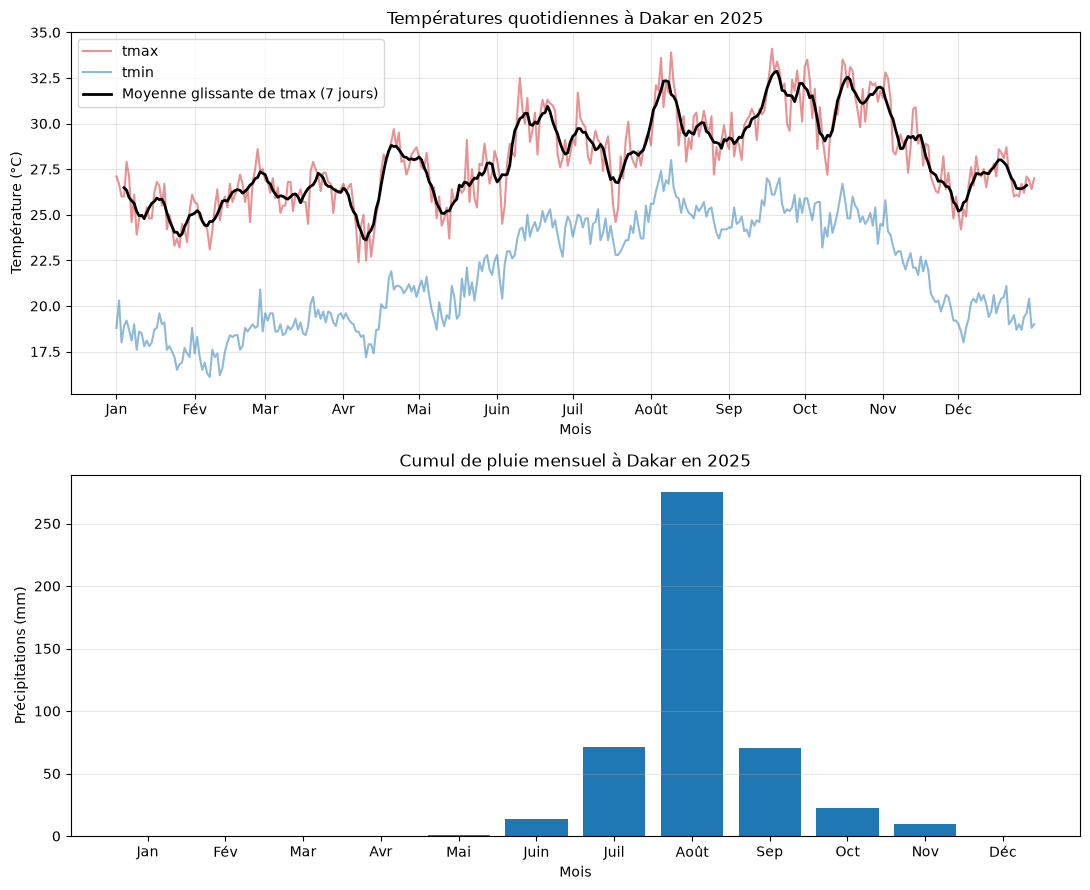

In [35]:
import matplotlib.pyplot as plt

jours = np.arange(365)
jours_glissante = np.arange(3, 362)                 # centre de chaque fenêtre de 7 jours
debuts_mois = np.cumsum(nb_jours) - nb_jours        # position du 1er jour de chaque mois

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9))

# Graphique du haut : températures
ax1.plot(jours, tmax, label="tmax", color="tab:red", alpha=0.5)
ax1.plot(jours, tmin, label="tmin", color="tab:blue", alpha=0.5)
ax1.plot(jours_glissante, moy_glissante, label="Moyenne glissante de tmax (7 jours)",
         color="black", linewidth=2)
ax1.set_title("Températures quotidiennes à Dakar en 2025")
ax1.set_xlabel("Mois")
ax1.set_ylabel("Température (°C)")
ax1.set_xticks(debuts_mois)
ax1.set_xticklabels(NOMS_MOIS)
ax1.legend()
ax1.grid(alpha=0.3)

# Graphique du bas : cumul de pluie mensuel
ax2.bar(NOMS_MOIS, cumul_pluie, color="tab:blue")
ax2.set_title("Cumul de pluie mensuel à Dakar en 2025")
ax2.set_xlabel("Mois")
ax2.set_ylabel("Précipitations (mm)")
ax2.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

**B.2 — Interprétation.** Le graphique du haut montre une saison fraîche de janvier à mai (tmax autour de 25-27 °C), puis une montée nette dès juin jusqu'au maximum de septembre-octobre. La moyenne glissante lisse les variations quotidiennes et rend la tendance saisonnière lisible. Les tmin suivent la même forme, décalées d'environ 6 °C vers le bas. Le diagramme du bas montre que la pluie est concentrée entre juin et octobre, avec un pic très marqué en août (275,2 mm).